# Grapheme-Color Synesthesia: Do Embedding Similarities Predict Synesthetic Associations?

**Research question**: Does the cosine similarity between letter and color representations in Word2Vec or GPT embedding space predict which letter-color pairs are most common in grapheme-color synesthetes?

**Data**: Witthoft, Winawer & Eagleman (2015, *PLoS ONE*) — 6,588 English-speaking synesthetes; each selected a color for every letter A–Z using a color picker. Dataset available at [Zenodo DOI 10.5281/zenodo.14285](http://dx.doi.org/10.5281/zenodo.14285).

**Embeddings compared**:
- **Word2Vec** (Google News, 300d): static distributional embeddings, trained on 100B words
- **GPT** (`text-embedding-3-small`): contextual OpenAI embeddings

**Pipeline**:
1. Convert each synesthete's RGB pick → one of 11 basic color labels → letter×color frequency matrix
2. Compute letter–color cosine similarity under each embedding model
3. Correlate the two similarity matrices with the empirical frequency matrix


---
## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import scipy.io
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 120, 'figure.figsize': (13, 7)})
print('Imports OK')

Imports OK


In [2]:
LETTERS = list('ABCDEFGHIJKLMNOPQRSTUVWXYZ')

# 11 basic color labels (0-10) as defined in Witthoft et al. / Berlin & Kay
COLOR_NAMES = ['Black', 'White', 'Red', 'Green', 'Yellow', 'Blue', 'Brown', 'Purple', 'Pink', 'Orange', 'Gray']
COLOR_WORDS  = [c.lower() for c in COLOR_NAMES]  # for embedding queries

# Approximate display colors for matplotlib
DISPLAY_HEX = {
    'Black':  '#1a1a1a', 'White':  '#e8e8e8', 'Red':    '#e63946',
    'Green':  '#2dc653', 'Yellow': '#ffd166', 'Blue':   '#4361ee',
    'Brown':  '#8b4513', 'Purple': '#9b2dca', 'Pink':   '#f72585',
    'Orange': '#f4a261', 'Gray':   '#9e9e9e',
}

DATA_DIR = Path('data')
print(f'Colors: {COLOR_NAMES}')
print(f'Letters: {LETTERS}')

Colors: ['Black', 'White', 'Red', 'Green', 'Yellow', 'Blue', 'Brown', 'Purple', 'Pink', 'Orange', 'Gray']
Letters: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


---
## 2. Synesthesia Ground Truth
### 2a. Load Eagleman data

In [3]:
mat       = scipy.io.loadmat(DATA_DIR / 'EaglemanColoredAlphabets.mat')
lrgb_mat  = scipy.io.loadmat(DATA_DIR / 'lRGBnathan.mat')

# u_rgb: (6588, 4, 26)  — column 0 is a db row-index; columns 1-3 are R,G,B in [0,1]
rgb_data   = mat['u_rgb'][:, 1:4, :]   # → (6588, 3, 26)
label_grid = lrgb_mat['labeledRGB']     # → (9, 9, 12) human-labeled lookup table

print(f'Subjects : {rgb_data.shape[0]:,}')
print(f'Letters  : {rgb_data.shape[2]}')
print(f'Color label grid : {label_grid.shape}  (values 0–{label_grid.max()})')
print(f'NaN rate : {np.mean(np.isnan(rgb_data[:,0,:])):.1%}  (subjects who skipped a letter)')

Subjects : 6,588
Letters  : 26
Color label grid : (9, 9, 12)  (values 0–10)
NaN rate : 4.3%  (subjects who skipped a letter)


### 2b. Classify RGB → basic color label

The lookup table maps a discretized RGB grid (9×9×12 points) to the 11 Berlin & Kay color labels, collected via a human color-naming experiment. We find the nearest grid cell for each synesthete's RGB pick.

In [4]:
# Grid axes
_r_grid = np.linspace(0, 255, label_grid.shape[0])
_g_grid = np.linspace(0, 255, label_grid.shape[1])
_b_grid = np.linspace(0, 255, label_grid.shape[2])

def classify_rgb_batch(rgb_arr):
    """Classify (N,3) RGB array in [0,1] → array of color label ints (-1 = missing)."""
    labels = np.full(len(rgb_arr), -1, dtype=np.int8)
    for i, (r, g, b) in enumerate(rgb_arr):
        if np.isnan(r):
            continue
        ri = int(np.argmin(np.abs(_r_grid - r * 255)))
        gi = int(np.argmin(np.abs(_g_grid - g * 255)))
        bi = int(np.argmin(np.abs(_b_grid - b * 255)))
        labels[i] = label_grid[ri, gi, bi]
    return labels

# Sanity check
test_cases = [(1.0, 0.0, 0.0, 'Red'), (0.0, 0.0, 1.0, 'Blue'),
              (1.0, 1.0, 0.0, 'Yellow'), (0.0, 0.0, 0.0, 'Black')]
for r, g, b, expected in test_cases:
    lbl = classify_rgb_batch(np.array([[r, g, b]]))[0]
    print(f'RGB({r:.0f},{g:.0f},{b:.0f}) → {COLOR_NAMES[lbl]:8s}  (expected {expected})')

RGB(1,0,0) → Red       (expected Red)
RGB(0,0,1) → Blue      (expected Blue)
RGB(1,1,0) → Yellow    (expected Yellow)
RGB(0,0,0) → Black     (expected Black)


### 2c. Build letter × color frequency matrix

In [5]:
n_letters = len(LETTERS)
n_colors  = len(COLOR_NAMES)

# freq_matrix[letter_i, color_j] = fraction of synesthetes who pick color j for letter i
freq_matrix = np.zeros((n_letters, n_colors))

for li in range(n_letters):
    batch  = rgb_data[:, :, li]                  # (6588, 3)
    labels = classify_rgb_batch(batch)
    valid  = labels[labels >= 0]
    for ci in range(n_colors):
        freq_matrix[li, ci] = np.sum(valid == ci) / len(valid)

freq_df = pd.DataFrame(freq_matrix, index=LETTERS, columns=COLOR_NAMES)

print('Modal color per letter:')
for letter, row in freq_df.iterrows():
    top = row.idxmax()
    print(f'  {letter}: {top:8s} ({row[top]:.1%})')

Modal color per letter:
  A: Red      (54.0%)
  B: Blue     (41.0%)
  C: Yellow   (36.5%)
  D: Blue     (19.4%)
  E: Green    (24.7%)
  F: Green    (24.3%)
  G: Green    (33.9%)
  H: Orange   (28.4%)
  I: White    (36.4%)
  J: Orange   (17.1%)
  K: Orange   (18.2%)
  L: Yellow   (27.0%)
  M: Red      (31.1%)
  N: Orange   (25.8%)
  O: White    (37.9%)
  P: Purple   (18.0%)
  Q: Purple   (22.3%)
  R: Red      (38.2%)
  S: Yellow   (25.4%)
  T: Blue     (20.7%)
  U: Yellow   (17.0%)
  V: Purple   (21.3%)
  W: Blue     (25.6%)
  X: Black    (30.6%)
  Y: Yellow   (46.3%)
  Z: Black    (30.4%)


### 2d. Visualize synesthesia frequencies

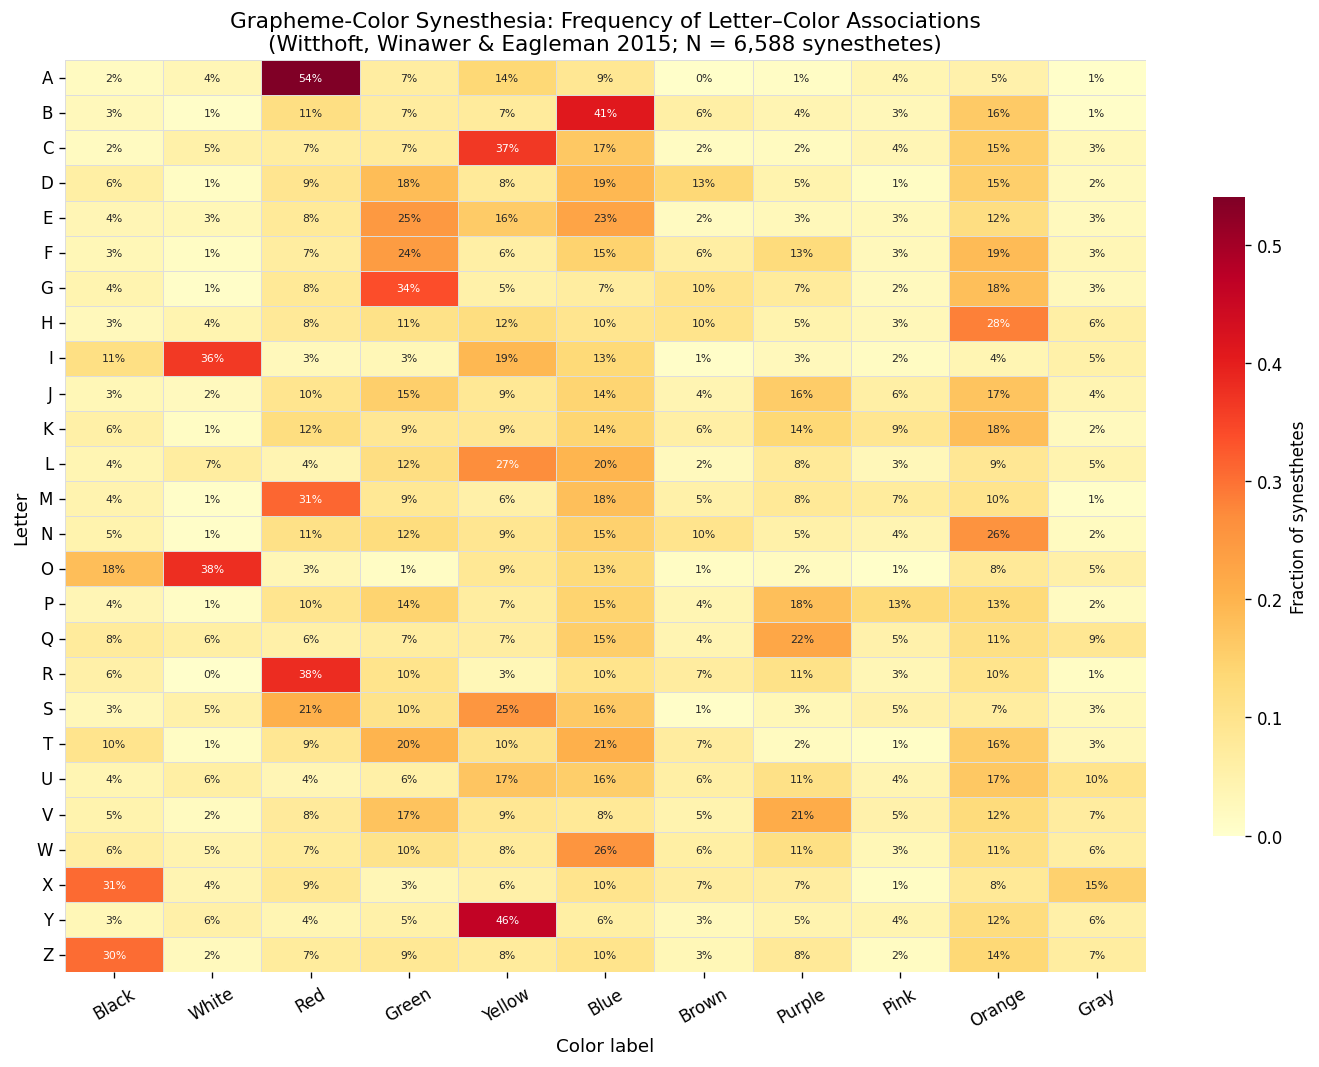

In [6]:
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    freq_df,
    ax=ax,
    cmap='YlOrRd',
    linewidths=0.3,
    linecolor='#dddddd',
    annot=True,
    fmt='.0%',
    annot_kws={'size': 6.5},
    cbar_kws={'label': 'Fraction of synesthetes', 'shrink': 0.7},
    vmin=0,
    vmax=freq_matrix.max()
)

ax.set_title('Grapheme-Color Synesthesia: Frequency of Letter–Color Associations\n'
             '(Witthoft, Winawer & Eagleman 2015; N = 6,588 synesthetes)', fontsize=13)
ax.set_xlabel('Color label', fontsize=11)
ax.set_ylabel('Letter', fontsize=11)
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

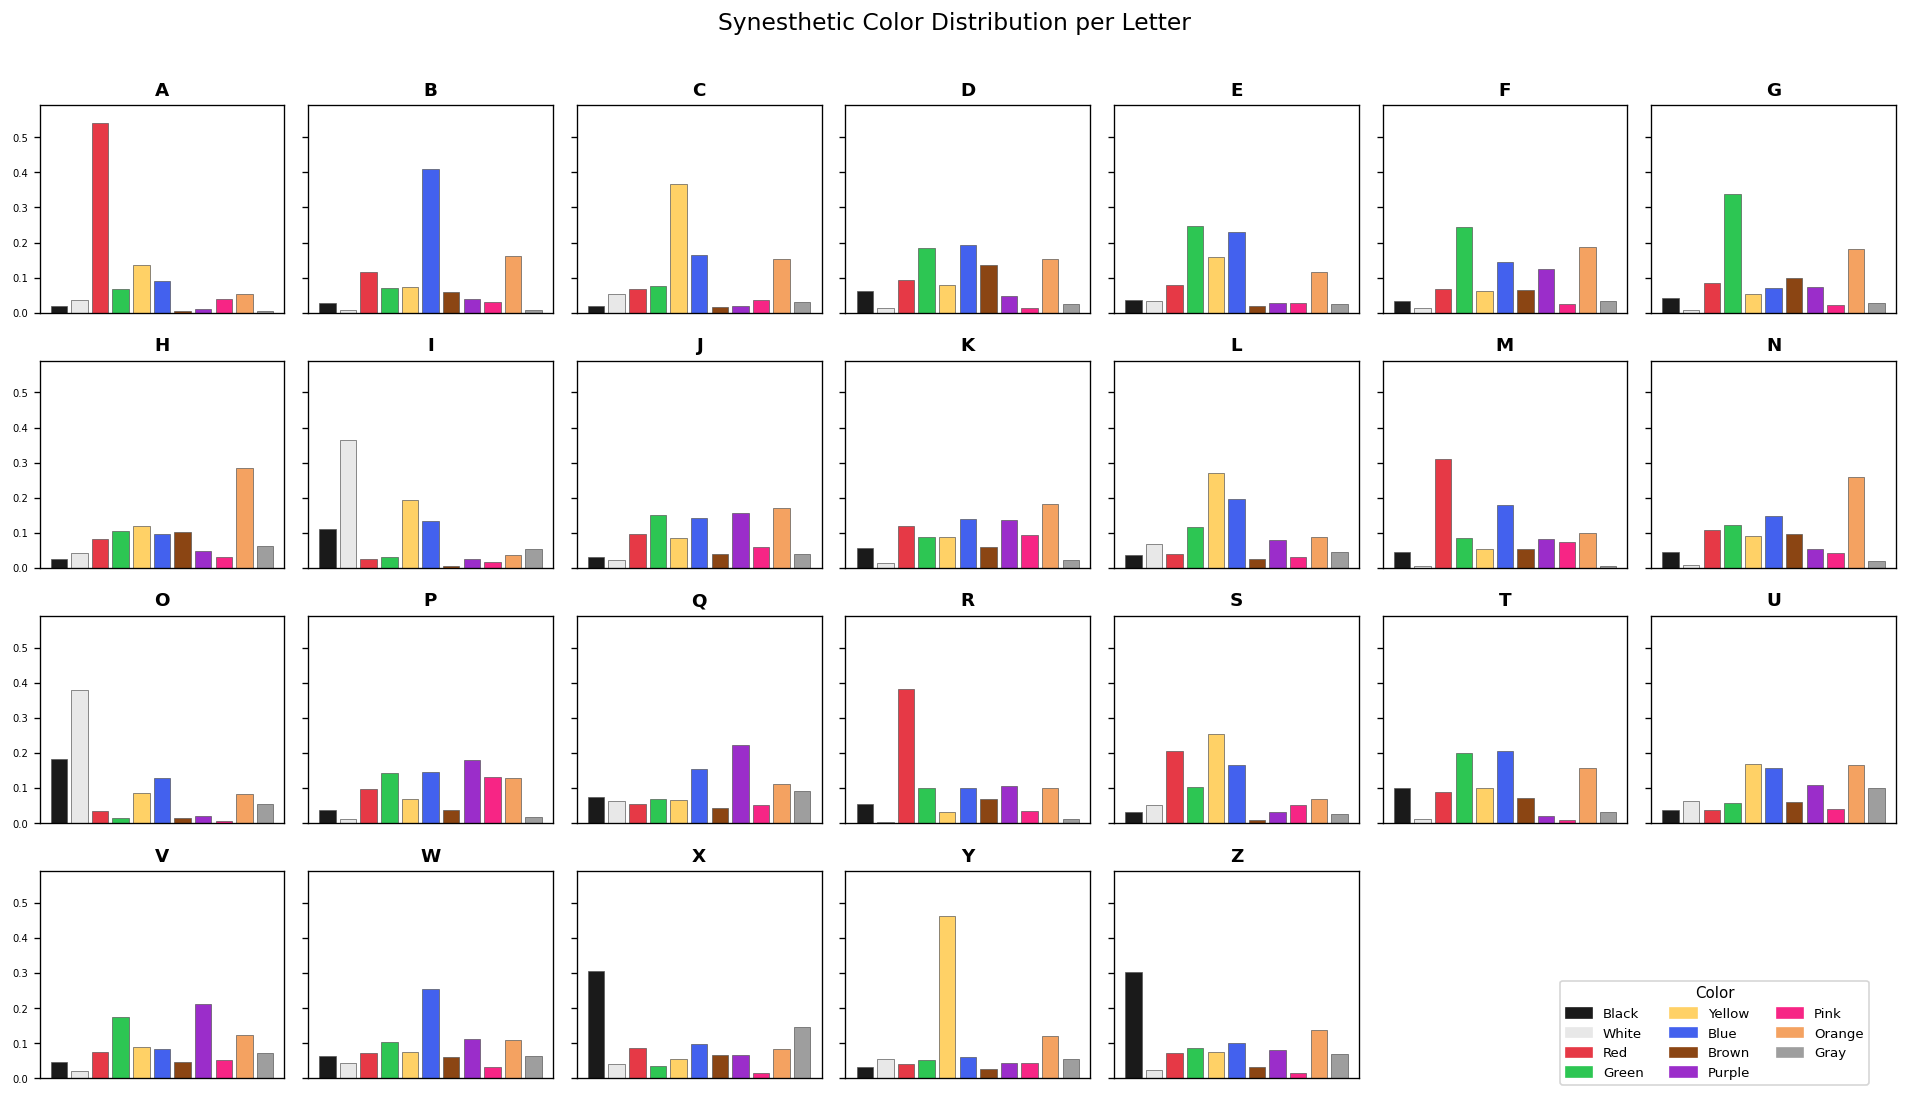

In [7]:
# Bar chart: modal color for each letter
fig, axes = plt.subplots(4, 7, figsize=(16, 9), sharey=True)
axes_flat = axes.flatten()

for i, (letter, row) in enumerate(freq_df.iterrows()):
    ax = axes_flat[i]
    colors_hex = [DISPLAY_HEX[c] for c in COLOR_NAMES]
    bars = ax.bar(range(n_colors), row.values, color=colors_hex,
                  edgecolor='#555', linewidth=0.4)
    ax.set_title(letter, fontsize=11, fontweight='bold')
    ax.set_xticks([])
    ax.set_ylim(0, freq_matrix.max() + 0.05)
    ax.tick_params(labelsize=6)

# Remove unused subplots (26 letters, 28 cells)
for j in range(len(LETTERS), len(axes_flat)):
    axes_flat[j].set_visible(False)

# Legend
legend_patches = [mpatches.Patch(color=DISPLAY_HEX[c], label=c) for c in COLOR_NAMES]
fig.legend(handles=legend_patches, loc='lower right', ncol=3, fontsize=8,
           title='Color', title_fontsize=9, bbox_to_anchor=(0.98, 0.01))

fig.suptitle('Synesthetic Color Distribution per Letter', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

---
## 3. Word2Vec Embeddings (Google News, 300d)

We load Google News word2vec via `gensim.downloader`. **First download is ~1.7 GB compressed** and will take a few minutes; subsequent runs load from the local cache at `~/gensim-data/`.

For each letter we use the uppercase single-character token (e.g. `"A"`). In the Google News corpus these appear in contexts like "Plan A", "Type A", "Class A", etc. For colors we use the lowercase color word (e.g. `"red"`).

> **Faster alternative**: swap `MODEL_NAME` to `'glove-wiki-gigaword-300'` (394 MB). GloVe is a closely related static embedding algorithm and will give comparable results.

In [8]:
import gensim.downloader as gensim_api

MODEL_NAME = 'word2vec-google-news-300'  # swap to 'glove-wiki-gigaword-300' for 376 MB download

print(f'Loading "{MODEL_NAME}" …  (downloads on first run)')
w2v = gensim_api.load(MODEL_NAME)
print(f'Loaded! Vocabulary size: {len(w2v):,}')

Loading "word2vec-google-news-300" …  (downloads on first run)
Loaded! Vocabulary size: 3,000,000


In [9]:
def get_letter_vector_w2v(letter, model):
    """
    Strategy: try uppercase single char; fall back to phonetic letter name.
    Phonetic names are unambiguous for most letters when prefixed with 'letter_'.
    """
    phonetics = {
        'A':'ay','B':'bee','C':'see','D':'dee','E':'ee','F':'eff','G':'gee',
        'H':'aitch','I':'eye','J':'jay','K':'kay','L':'el','M':'em',
        'N':'en','O':'oh','P':'pee','Q':'cue','R':'ar','S':'ess',
        'T':'tee','U':'you','V':'vee','W':'double_u','X':'ex','Y':'why','Z':'zee'
    }
    if letter in model:
        return model[letter]
    phon = phonetics[letter]
    if phon in model:
        return model[phon]
    # Average 'letter' vector and uppercase char
    vecs = [model[t] for t in ['letter', letter.lower()] if t in model]
    if vecs:
        return np.mean(vecs, axis=0)
    return None

# Collect vectors
letter_vecs_w2v = {}
missing_letters  = []
for letter in LETTERS:
    vec = get_letter_vector_w2v(letter, w2v)
    if vec is not None:
        letter_vecs_w2v[letter] = vec
    else:
        missing_letters.append(letter)

color_vecs_w2v = {c: w2v[c] for c in COLOR_WORDS if c in w2v}
missing_colors = [c for c in COLOR_WORDS if c not in w2v]

print(f'Letters found: {len(letter_vecs_w2v)}/26  (missing: {missing_letters or "none"})')
print(f'Colors found : {len(color_vecs_w2v)}/11  (missing: {missing_colors or "none"})')

Letters found: 26/26  (missing: none)
Colors found : 11/11  (missing: none)


In [10]:
def cosine_sim_matrix(letter_dict, color_dict, letter_order, color_order):
    """Build (n_letters, n_colors) cosine similarity matrix."""
    L = np.array([letter_dict[l] for l in letter_order])  # (26, dim)
    C = np.array([color_dict[c] for c in color_order])    # (11, dim)
    # Normalize rows
    L_norm = L / np.linalg.norm(L, axis=1, keepdims=True)
    C_norm = C / np.linalg.norm(C, axis=1, keepdims=True)
    return L_norm @ C_norm.T   # (26, 11)


def cosine_sim_matrix_np(A, B):
    """Cosine similarity between rows of A (n,d) and rows of B (m,d) → (n,m)."""
    A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
    B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)
    return A_norm @ B_norm.T

w2v_sim = cosine_sim_matrix(letter_vecs_w2v, color_vecs_w2v, LETTERS, COLOR_WORDS)
w2v_sim_df = pd.DataFrame(w2v_sim, index=LETTERS, columns=COLOR_NAMES)

print('Word2Vec similarity matrix (sample):')
print(w2v_sim_df.head())

Word2Vec similarity matrix (sample):
      Black     White       Red     Green    Yellow      Blue     Brown  \
A  0.101211  0.141892  0.087164  0.014439  0.085444  0.084093  0.074679   
B  0.070348  0.083933  0.078786  0.001345  0.098671  0.048381  0.070279   
C  0.042757  0.024532  0.104307 -0.013713  0.083731  0.098820  0.062581   
D  0.072148  0.028309  0.055496  0.049342  0.038177  0.093615 -0.008765   
E  0.029910  0.019845  0.086605  0.095431  0.104345  0.085803  0.036369   

     Purple      Pink    Orange      Gray  
A  0.053845  0.084135  0.097170  0.086068  
B  0.042193  0.063955  0.067518  0.066034  
C  0.061438  0.072487  0.096443  0.098509  
D  0.054728  0.032560  0.045256  0.011113  
E  0.053381  0.015464  0.060382  0.100555  


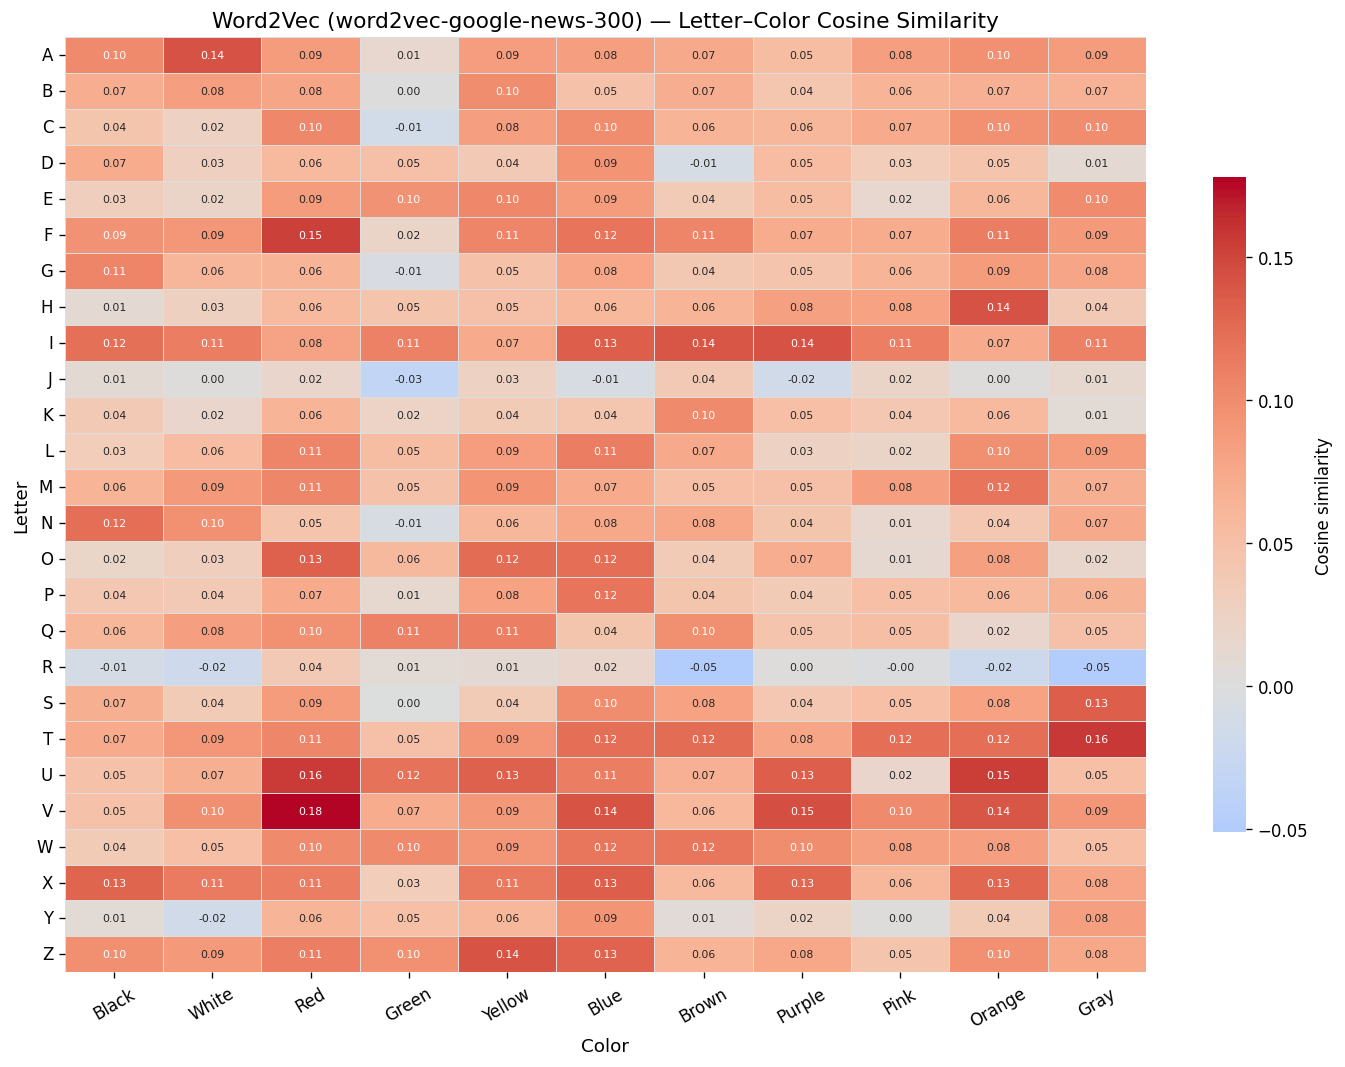

In [11]:
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    w2v_sim_df,
    ax=ax,
    cmap='coolwarm',
    center=0,
    linewidths=0.3,
    linecolor='#dddddd',
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6.5},
    cbar_kws={'label': 'Cosine similarity', 'shrink': 0.7},
)

ax.set_title(f'Word2Vec ({MODEL_NAME}) — Letter–Color Cosine Similarity', fontsize=13)
ax.set_xlabel('Color', fontsize=11)
ax.set_ylabel('Letter', fontsize=11)
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

---
## 3b. Word2Vec Embeddings (Literary — trained on Project Gutenberg novels)

We download ~50 classic English novels from Project Gutenberg and train a fresh word2vec model on them. This lets us ask: does a model that only ever read fiction capture synesthetic associations differently from one trained on news text?

**Training setup**: same architecture as Google News (skip-gram, 300d, window=5) but trained from scratch on ~5–10M words of literary prose. More epochs (20) compensate for the smaller corpus.

> First run downloads ~50 novels (~50 MB total) and trains in a few minutes. The model is cached to `data/literary_w2v.model`.

In [12]:
import requests, re, time
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

# Curated list of classic English novels on Project Gutenberg
NOVELS = [
    (1342, "Pride and Prejudice"),    (158,  "Emma"),
    (105,  "Persuasion"),             (161,  "Sense and Sensibility"),
    (163,  "Northanger Abbey"),       (1260, "Jane Eyre"),
    (768,  "Wuthering Heights"),      (98,   "A Tale of Two Cities"),
    (1400, "Great Expectations"),     (730,  "Oliver Twist"),
    (46,   "A Christmas Carol"),      (766,  "David Copperfield"),
    (84,   "Frankenstein"),           (345,  "Dracula"),
    (43,   "Jekyll and Hyde"),        (174,  "The Picture of Dorian Gray"),
    (11,   "Alice in Wonderland"),    (12,   "Through the Looking-Glass"),
    (55,   "The Wonderful Wizard of Oz"), (16, "Peter Pan"),
    (74,   "Tom Sawyer"),             (76,   "Huckleberry Finn"),
    (2701, "Moby Dick"),              (521,  "The Scarlet Letter"),
    (514,  "Little Women"),           (45,   "Anne of Green Gables"),
    (5740, "The Awakening"),          (209,  "The Turn of the Screw"),
    (1661, "Sherlock Holmes"),        (244,  "A Study in Scarlet"),
    (120,  "Treasure Island"),        (1064, "The Call of the Wild"),
    (219,  "Heart of Darkness"),      (2814, "Dubliners"),
    (35,   "The Time Machine"),       (36,   "The War of the Worlds"),
    (786,  "Tess of the d'Urbervilles"), (107, "Far from the Madding Crowd"),
    (2097, "Robinson Crusoe"),        (33,   "The Scarlet Pimpernel"),
    (580,  "The Jungle"),             (5200, "Metamorphosis"),
    (2600, "War and Peace"),          (2413, "The Brothers Karamazov"),
    (1184, "The Count of Monte Cristo"), (1251, "The Three Musketeers"),
    (996,  "Don Quixote"),            (135,  "Les Misérables"),
    (4300, "Ulysses"),                (1399, "Anna Karenina"),
]

def fetch_book(gid):
    for url in [
        f"https://gutenberg.org/cache/epub/{gid}/pg{gid}.txt",
        f"https://gutenberg.org/files/{gid}/{gid}-0.txt",
        f"https://gutenberg.org/files/{gid}/{gid}.txt",
    ]:
        try:
            r = requests.get(url, timeout=25, headers={'User-Agent': 'synesthesia-research/1.0'})
            if r.status_code == 200:
                return r.text
        except Exception:
            pass
    return None

def strip_gutenberg(text):
    start = re.search(r'\*\*\*\s*START OF (THIS|THE) PROJECT GUTENBERG', text, re.I)
    end   = re.search(r'\*\*\*\s*END OF (THIS|THE) PROJECT GUTENBERG',   text, re.I)
    if start:
        text = text[text.index('\n', start.start()) + 1:]
    if end:
        text = text[:end.start()]
    return text.strip()

# Download (skip if already cached)
corpus_path = DATA_DIR / 'gutenberg_corpus.txt'

if corpus_path.exists():
    print(f'Corpus already cached at {corpus_path}  ({corpus_path.stat().st_size / 1e6:.1f} MB)')
else:
    print(f'Downloading {len(NOVELS)} novels from Project Gutenberg…')
    total_words = 0
    with open(corpus_path, 'w', encoding='utf-8') as f_out:
        for i, (gid, title) in enumerate(NOVELS):
            raw = fetch_book(gid)
            if raw is None:
                print(f'  [{i+1:02d}/{len(NOVELS)}] FAILED  : {title}')
                continue
            cleaned = strip_gutenberg(raw)
            words   = len(cleaned.split())
            total_words += words
            f_out.write(cleaned + '\n\n')
            print(f'  [{i+1:02d}/{len(NOVELS)}] {words:>7,}w  {title}')
            time.sleep(0.4)   # be polite to Gutenberg servers
    print(f'\nCorpus saved: {total_words:,} words total')

Corpus already cached at data/gutenberg_corpus.txt  (40.2 MB)


In [13]:
lit_model_path = DATA_DIR / 'literary_w2v.model'

if lit_model_path.exists():
    lit_w2v = Word2Vec.load(str(lit_model_path))
    print(f'Loaded cached model — vocab: {len(lit_w2v.wv):,} words')
else:
    print('Tokenising corpus…')
    sentences = []
    with open(corpus_path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if len(line) > 15:
                tokens = simple_preprocess(line, deacc=True)
                if tokens:
                    sentences.append(tokens)
    print(f'  {len(sentences):,} sentences')

    print('Training word2vec (skip-gram, 300d)…')
    lit_w2v = Word2Vec(
        sentences  = sentences,
        vector_size= 300,
        window     = 5,
        min_count  = 5,
        sg         = 1,    # skip-gram, same as Google News
        workers    = 4,
        epochs     = 20,
    )
    lit_w2v.save(str(lit_model_path))
    print(f'Trained and saved — vocab: {len(lit_w2v.wv):,} words')

Loaded cached model — vocab: 28,175 words


In [14]:
# Build letter and color vectors from literary model
# Use same strategy as Google News: uppercase single char with phonetic fallback
lit_letter_vecs = {}
lit_missing_letters = []
for letter in LETTERS:
    vec = get_letter_vector_w2v(letter, lit_w2v.wv)
    if vec is not None:
        lit_letter_vecs[letter] = vec
    else:
        lit_missing_letters.append(letter)

lit_color_vecs   = {c: lit_w2v.wv[c] for c in COLOR_WORDS if c in lit_w2v.wv}
lit_missing_col  = [c for c in COLOR_WORDS if c not in lit_w2v.wv]

print(f'Letters found: {len(lit_letter_vecs)}/26  (missing: {lit_missing_letters or "none"})')
print(f'Colors  found: {len(lit_color_vecs)}/11  (missing: {lit_missing_col or "none"})')

# Fall back: for any missing letter/color, use zero vector (won't affect other pairs)
for letter in lit_missing_letters:
    lit_letter_vecs[letter] = np.zeros(300)
for color in lit_missing_col:
    lit_color_vecs[color] = np.zeros(300)

lit_sim    = cosine_sim_matrix(lit_letter_vecs, lit_color_vecs, LETTERS, COLOR_WORDS)
lit_sim_df = pd.DataFrame(lit_sim, index=LETTERS, columns=COLOR_NAMES)

print('\nTop predicted color per letter (literary w2v):')
for i, letter in enumerate(LETTERS):
    top = np.argmax(lit_sim[i])
    print(f'  {letter}: {COLOR_NAMES[top]:8s} (sim={lit_sim[i,top]:.3f})')

Letters found: 26/26  (missing: none)
Colors  found: 11/11  (missing: none)

Top predicted color per letter (literary w2v):
  A: White    (sim=0.096)
  B: Orange   (sim=0.259)
  C: Brown    (sim=0.187)
  D: Pink     (sim=0.231)
  E: Gray     (sim=0.134)
  F: Pink     (sim=0.159)
  G: Orange   (sim=0.239)
  H: Pink     (sim=0.159)
  I: Yellow   (sim=0.148)
  J: Orange   (sim=0.396)
  K: Black    (sim=0.161)
  L: Green    (sim=0.178)
  M: White    (sim=0.166)
  N: White    (sim=0.118)
  O: Gray     (sim=0.128)
  P: Pink     (sim=0.159)
  Q: Gray     (sim=0.217)
  R: Orange   (sim=0.205)
  S: Green    (sim=0.183)
  T: Pink     (sim=0.159)
  U: Gray     (sim=0.146)
  V: Pink     (sim=0.159)
  W: Pink     (sim=0.159)
  X: Black    (sim=0.143)
  Y: Orange   (sim=0.144)
  Z: Pink     (sim=0.159)


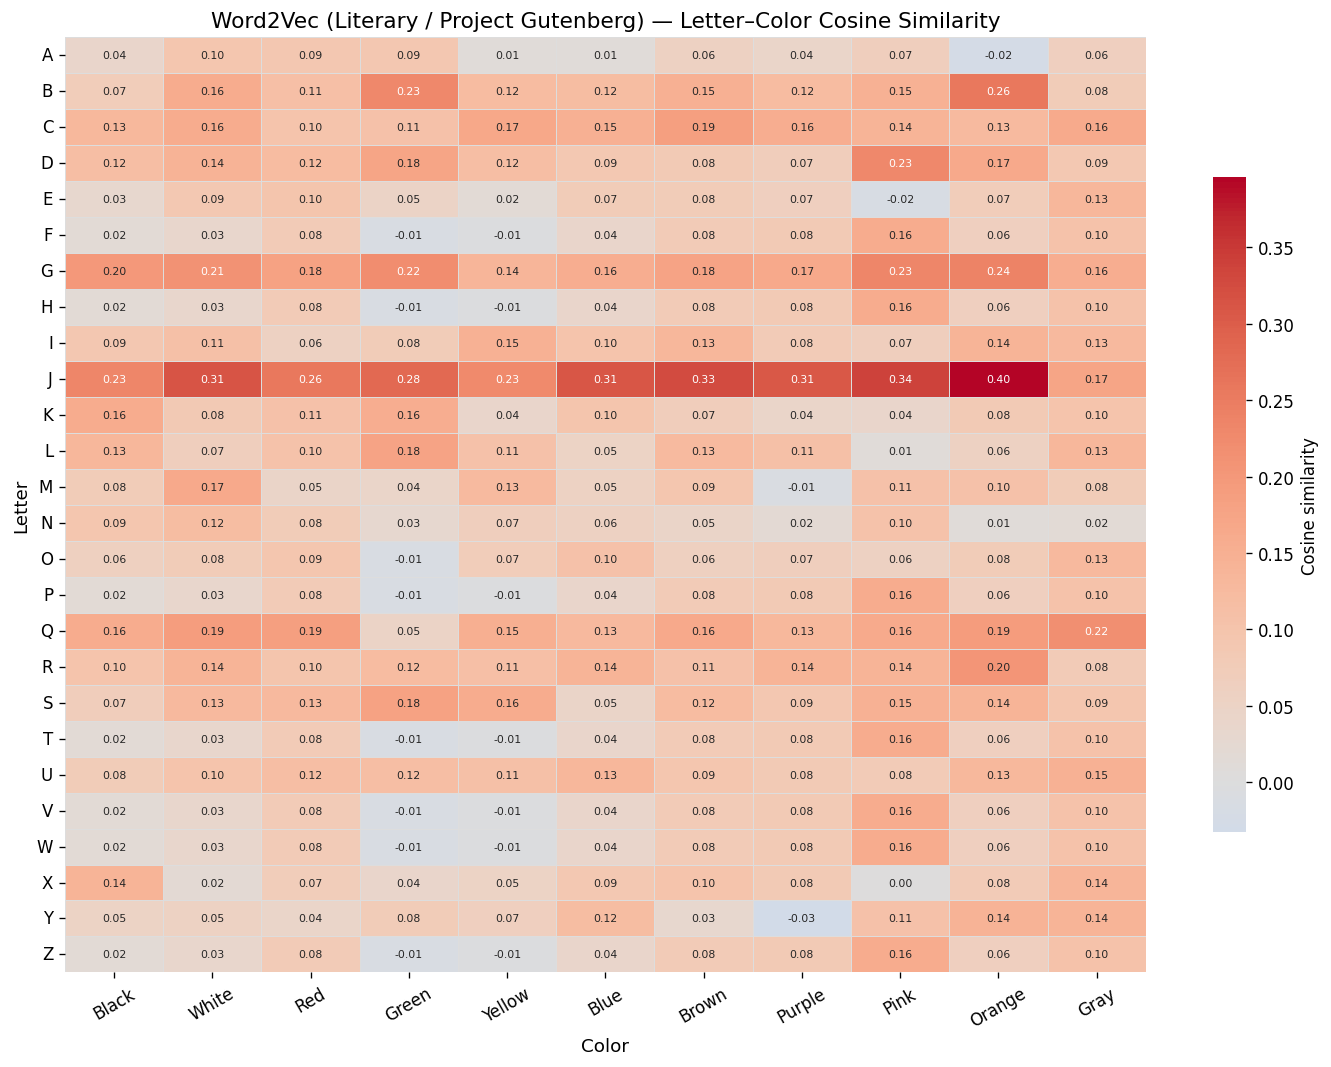

In [15]:
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    lit_sim_df, ax=ax, cmap='coolwarm', center=0,
    linewidths=0.3, linecolor='#dddddd',
    annot=True, fmt='.2f', annot_kws={'size': 6.5},
    cbar_kws={'label': 'Cosine similarity', 'shrink': 0.7},
)
ax.set_title('Word2Vec (Literary / Project Gutenberg) — Letter–Color Cosine Similarity', fontsize=13)
ax.set_xlabel('Color', fontsize=11)
ax.set_ylabel('Letter', fontsize=11)
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

In [16]:
# Phonetic letter names — lookup into the ALREADY-TRAINED literary model, no retraining
PHONETIC = {
    'A':'ay',  'B':'bee', 'C':'see',   'D':'dee', 'E':'ee',
    'F':'eff', 'G':'gee', 'H':'aitch', 'I':'eye', 'J':'jay',
    'K':'kay', 'L':'el',  'M':'em',    'N':'en',  'O':'oh',
    'P':'pee', 'Q':'cue', 'R':'ar',    'S':'ess', 'T':'tee',
    'U':'you', 'V':'vee', 'W':'dub',   'X':'ex',  'Y':'why', 'Z':'zee'
}

phon_letter_vecs = {}
phon_missing = []
for letter, phon in PHONETIC.items():
    if phon in lit_w2v.wv:
        phon_letter_vecs[letter] = lit_w2v.wv[phon]
    else:
        phon_missing.append(f'{letter}({phon})')
        phon_letter_vecs[letter] = np.zeros(300)

print(f'Phonetic names found in literary vocab: {26 - len(phon_missing)}/26')
if phon_missing:
    print(f'Missing (set to zero similarity): {phon_missing}')

phon_sim    = cosine_sim_matrix(phon_letter_vecs, lit_color_vecs, LETTERS, COLOR_WORDS)
phon_sim    = np.nan_to_num(phon_sim, nan=0.0)   # zero-vec fallback → 0, not NaN
phon_sim_df = pd.DataFrame(phon_sim, index=LETTERS, columns=COLOR_NAMES)

print('\nTop predicted color per letter (literary w2v, phonetic):')
for i, letter in enumerate(LETTERS):
    top  = np.argmax(phon_sim[i])
    phon = PHONETIC[letter]
    print(f'  {letter} ("{phon}"): {COLOR_NAMES[top]:8s} (sim={phon_sim[i,top]:.3f})')

Phonetic names found in literary vocab: 20/26
Missing (set to zero similarity): ['F(eff)', 'H(aitch)', 'P(pee)', 'T(tee)', 'V(vee)', 'Z(zee)']

Top predicted color per letter (literary w2v, phonetic):
  A ("ay"): White    (sim=0.096)
  B ("bee"): Orange   (sim=0.259)
  C ("see"): Brown    (sim=0.187)
  D ("dee"): Pink     (sim=0.231)
  E ("ee"): Gray     (sim=0.134)
  F ("eff"): Black    (sim=0.000)
  G ("gee"): Orange   (sim=0.239)
  H ("aitch"): Black    (sim=0.000)
  I ("eye"): Yellow   (sim=0.148)
  J ("jay"): Orange   (sim=0.396)
  K ("kay"): Black    (sim=0.161)
  L ("el"): Green    (sim=0.178)
  M ("em"): White    (sim=0.166)
  N ("en"): White    (sim=0.118)
  O ("oh"): Gray     (sim=0.128)
  P ("pee"): Black    (sim=0.000)
  Q ("cue"): Gray     (sim=0.217)
  R ("ar"): Orange   (sim=0.205)
  S ("ess"): Green    (sim=0.183)
  T ("tee"): Black    (sim=0.000)
  U ("you"): Gray     (sim=0.146)
  V ("vee"): Black    (sim=0.000)
  W ("dub"): Purple   (sim=0.288)
  X ("ex"): Black    (

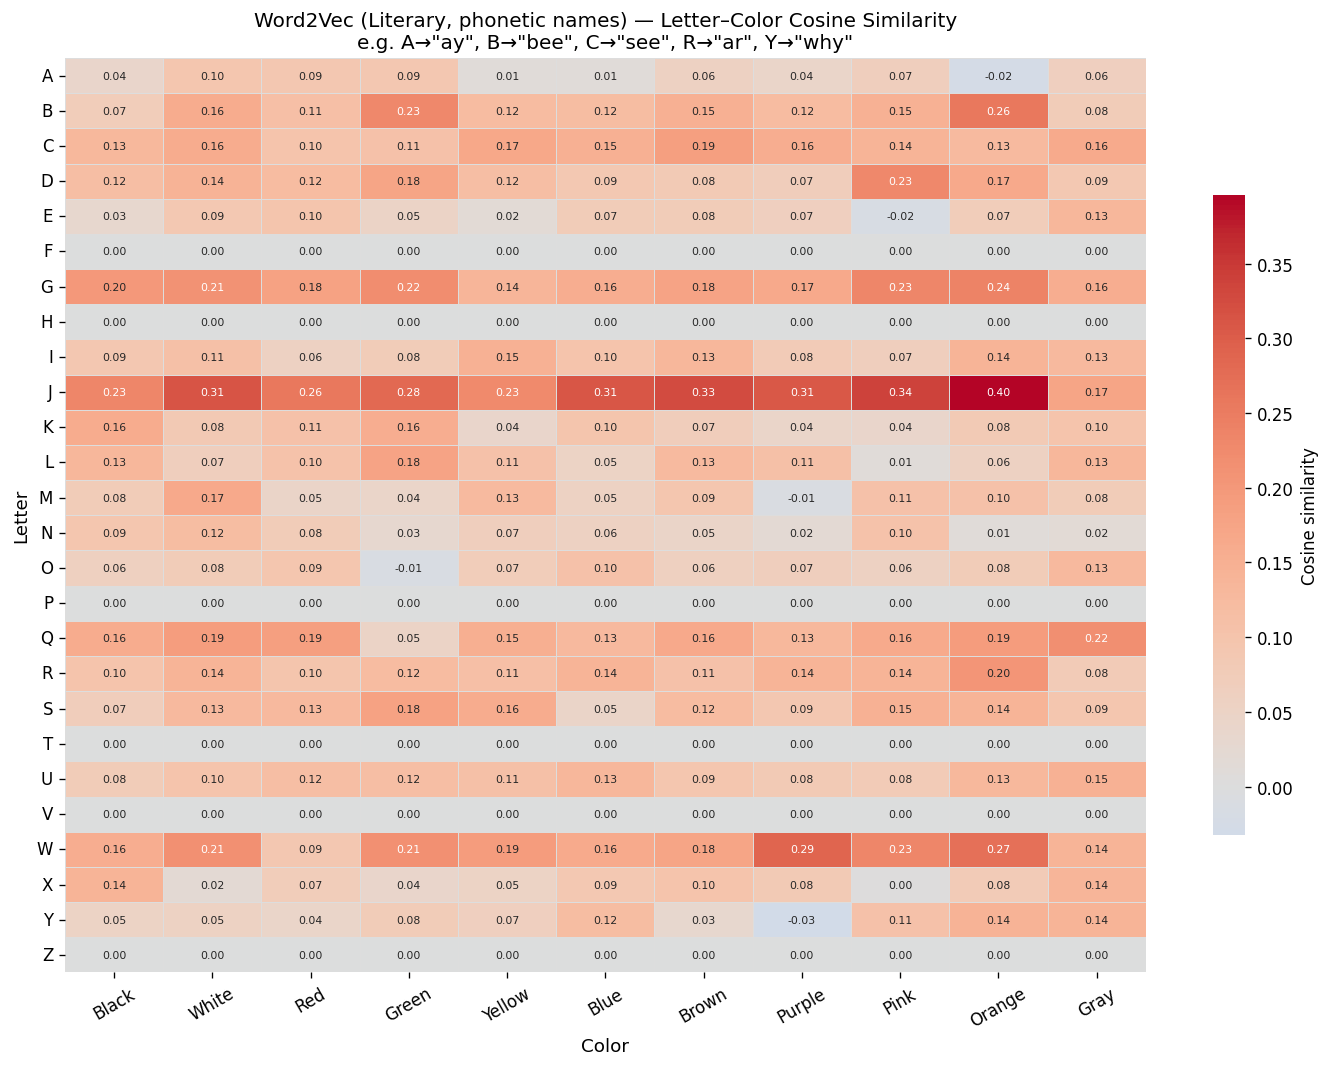

In [17]:
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    phon_sim_df, ax=ax, cmap='coolwarm', center=0,
    linewidths=0.3, linecolor='#dddddd',
    annot=True, fmt='.2f', annot_kws={'size': 6.5},
    cbar_kws={'label': 'Cosine similarity', 'shrink': 0.7},
)
ax.set_title('Word2Vec (Literary, phonetic names) — Letter–Color Cosine Similarity\n'
             'e.g. A→"ay", B→"bee", C→"see", R→"ar", Y→"why"', fontsize=12)
ax.set_xlabel('Color', fontsize=11)
ax.set_ylabel('Letter', fontsize=11)
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

---
## 4. GPT Embeddings (`text-embedding-3-small`)

We call the OpenAI embeddings API using explicit phrases: `"the letter A"` and `"the color red"`. This disambiguates single letters from other uses and gives the model clear context.

Make sure `OPENAI_API_KEY` is set in your environment, or set it in the cell below.

In [18]:
import os
from openai import OpenAI

# Key is set via OPENAI_API_KEY environment variable (see ~/.zshrc)
# Uncomment to override: os.environ['OPENAI_API_KEY'] = 'sk-...'

client = OpenAI()
GPT_MODEL = 'text-embedding-3-small'
print(f'Using model: {GPT_MODEL}')

Using model: text-embedding-3-small


In [19]:
# Build queries
letter_queries = [f'the letter {l}' for l in LETTERS]    # 26 queries
color_queries  = [f'the color {c}'  for c in COLOR_WORDS] # 11 queries
all_queries    = letter_queries + color_queries             # 37 total

print('Fetching embeddings from OpenAI…')
response = client.embeddings.create(
    model=GPT_MODEL,
    input=all_queries
)

all_embeddings = np.array([item.embedding for item in response.data])  # (37, 1536)
letter_embs_gpt = all_embeddings[:26]   # (26, 1536)
color_embs_gpt  = all_embeddings[26:]   # (11, 1536)

print(f'Embedding dim: {all_embeddings.shape[1]}')
print(f'Letter embeddings: {letter_embs_gpt.shape}')
print(f'Color embeddings : {color_embs_gpt.shape}')

Fetching embeddings from OpenAI…
Embedding dim: 1536
Letter embeddings: (26, 1536)
Color embeddings : (11, 1536)


In [20]:
# Cache embeddings locally to avoid re-calling the API
import json
cache = {
    'letter_queries': letter_queries,
    'color_queries':  color_queries,
    'letter_embs':    letter_embs_gpt.tolist(),
    'color_embs':     color_embs_gpt.tolist(),
    'model':          GPT_MODEL
}
with open(DATA_DIR / 'gpt_embeddings_cache.json', 'w') as f:
    json.dump(cache, f)
print('Saved to data/gpt_embeddings_cache.json')

Saved to data/gpt_embeddings_cache.json


In [21]:
# ── Run this cell instead of the API call if you already have the cache ──
cache_path = DATA_DIR / 'gpt_embeddings_cache.json'
if cache_path.exists():
    with open(cache_path) as f:
        cache = json.load(f)
    letter_embs_gpt = np.array(cache['letter_embs'])
    color_embs_gpt  = np.array(cache['color_embs'])
    GPT_MODEL       = cache['model']
    print(f'Loaded from cache. Model: {GPT_MODEL}, dim: {letter_embs_gpt.shape[1]}')
else:
    print('No cache found — run the API cell above first.')

Loaded from cache. Model: text-embedding-3-small, dim: 1536


### 4b. Completing the grid: phrasing × architecture

To isolate what's doing the work — **phrasing** ("A" vs "letter A" vs "the letter A") or **architecture** (static word2vec vs contextual GPT) — we need all four corners:

| | `"A"` / `"red"` | `"letter A"` / `"red"` | `"the letter A"` / `"the color red"` |
|---|---|---|---|
| **Word2Vec (Google News)** | ✓ already | ← adding now | — |
| **GPT** | ← adding now | ✓ already | ✓ already (original) |

In [22]:
# ── GPT bare: "A" / "red" ──────────────────────────────────────────────────
gpt_bare_cache = DATA_DIR / 'gpt_embeddings_cache_bare.json'

if gpt_bare_cache.exists():
    with open(gpt_bare_cache) as f:
        cb = json.load(f)
    letter_embs_bare = np.array(cb['letter_embs'])
    color_embs_bare  = np.array(cb['color_embs'])
    print('GPT bare: loaded from cache')
else:
    print('Fetching GPT bare embeddings ("A", "B", … / "red", "blue", …)…')
    resp_bare = client.embeddings.create(
        model=GPT_MODEL,
        input=LETTERS + COLOR_WORDS   # ["A","B",…,"Z","red","blue",…]
    )
    all_bare = np.array([e.embedding for e in resp_bare.data])
    letter_embs_bare = all_bare[:26]
    color_embs_bare  = all_bare[26:]
    with open(gpt_bare_cache, 'w') as f:
        json.dump({'letter_embs': letter_embs_bare.tolist(),
                   'color_embs':  color_embs_bare.tolist(), 'model': GPT_MODEL}, f)
    print('Done.')

gpt_bare_sim    = cosine_sim_matrix_np(letter_embs_bare, color_embs_bare)
gpt_bare_sim_df = pd.DataFrame(gpt_bare_sim, index=LETTERS, columns=COLOR_NAMES)

# ── GPT "letter A" / "red" ─────────────────────────────────────────────────
gpt2_cache_path = DATA_DIR / 'gpt_embeddings_cache_v2.json'

if gpt2_cache_path.exists():
    with open(gpt2_cache_path) as f:
        cache2 = json.load(f)
    letter_embs_gpt2 = np.array(cache2['letter_embs'])
    color_embs_gpt2  = np.array(cache2['color_embs'])
    print('GPT "letter A": loaded from cache')
else:
    print('Fetching GPT "letter A" / "red" embeddings…')
    resp2 = client.embeddings.create(
        model=GPT_MODEL,
        input=[f'letter {l}' for l in LETTERS] + COLOR_WORDS
    )
    all2 = np.array([e.embedding for e in resp2.data])
    letter_embs_gpt2 = all2[:26]
    color_embs_gpt2  = all2[26:]
    with open(gpt2_cache_path, 'w') as f:
        json.dump({'letter_embs': letter_embs_gpt2.tolist(),
                   'color_embs':  color_embs_gpt2.tolist(), 'model': GPT_MODEL}, f)
    print('Done.')

gpt2_sim    = cosine_sim_matrix_np(letter_embs_gpt2, color_embs_gpt2)
gpt2_sim_df = pd.DataFrame(gpt2_sim, index=LETTERS, columns=COLOR_NAMES)

# ── W2V Google News "letter A" (averaged vectors) ──────────────────────────
def get_letter_vector_phrase(letter, model):
    vecs = [model[t] for t in ['letter', letter] if t in model]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

phrase_letter_vecs = {l: get_letter_vector_phrase(l, w2v) for l in LETTERS}

w2v_phrase_sim    = cosine_sim_matrix(phrase_letter_vecs, color_vecs_w2v, LETTERS, COLOR_WORDS)
w2v_phrase_sim_df = pd.DataFrame(w2v_phrase_sim, index=LETTERS, columns=COLOR_NAMES)

print('\nAll new conditions computed.')

GPT bare: loaded from cache
GPT "letter A": loaded from cache

All new conditions computed.


In [23]:
gpt_sim = cosine_sim_matrix_np(letter_embs_gpt, color_embs_gpt)  # (26, 11)
gpt_sim_df = pd.DataFrame(gpt_sim, index=LETTERS, columns=COLOR_NAMES)

print('GPT similarity matrix (sample):')
print(gpt_sim_df.head())

GPT similarity matrix (sample):
      Black     White       Red     Green    Yellow      Blue     Brown  \
A  0.284546  0.310645  0.297213  0.258585  0.289652  0.275008  0.234781   
B  0.341461  0.273016  0.297433  0.275754  0.281323  0.358132  0.356277   
C  0.282378  0.312772  0.315815  0.313363  0.316215  0.309532  0.293386   
D  0.295851  0.273511  0.320097  0.268229  0.293626  0.307883  0.267692   
E  0.262910  0.293097  0.288656  0.335534  0.319931  0.302753  0.255039   

     Purple      Pink    Orange      Gray  
A  0.273497  0.283653  0.260944  0.245204  
B  0.271498  0.287267  0.248485  0.234058  
C  0.264792  0.267273  0.289148  0.265414  
D  0.279282  0.274826  0.265195  0.262327  
E  0.239059  0.267267  0.239084  0.249948  


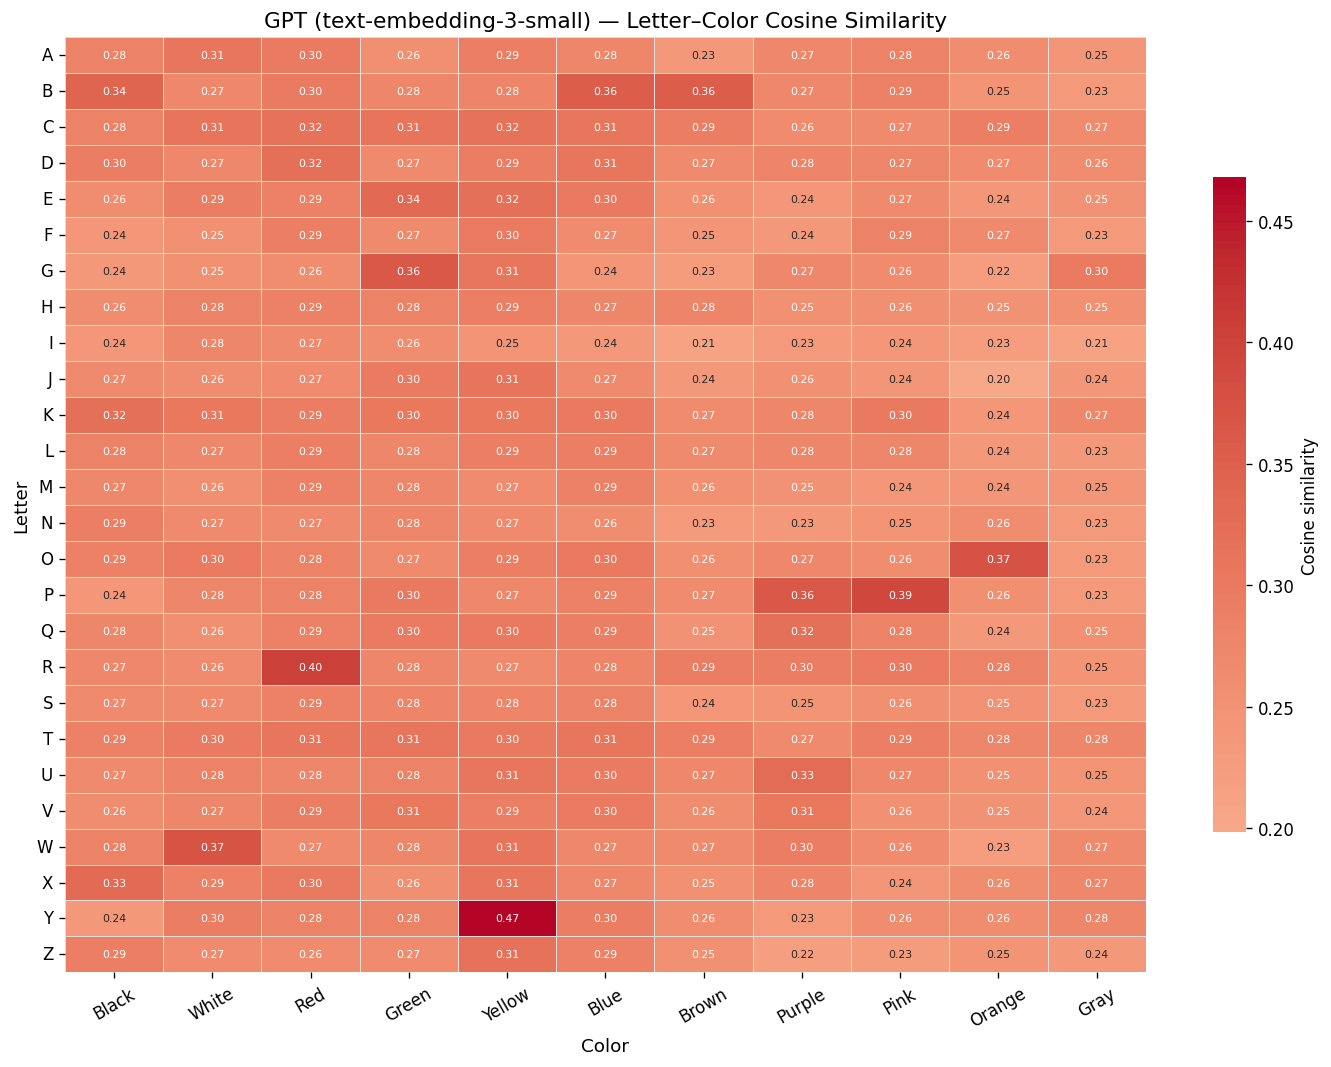

In [24]:
fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    gpt_sim_df,
    ax=ax,
    cmap='coolwarm',
    center=0,
    linewidths=0.3,
    linecolor='#dddddd',
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6.5},
    cbar_kws={'label': 'Cosine similarity', 'shrink': 0.7},
)

ax.set_title(f'GPT ({GPT_MODEL}) — Letter–Color Cosine Similarity', fontsize=13)
ax.set_xlabel('Color', fontsize=11)
ax.set_ylabel('Letter', fontsize=11)
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

---
## 5. Comparison: Embedding Similarity vs. Synesthetic Frequency

For each of the 26 × 11 = 286 letter–color pairs we have:
- `freq_matrix[i,j]` — fraction of synesthetes who pick color j for letter i
- `w2v_sim[i,j]` — Word2Vec cosine similarity
- `gpt_sim[i,j]` — GPT cosine similarity

We use **Spearman rank correlation** (nonparametric, robust to non-linearity) to compare.

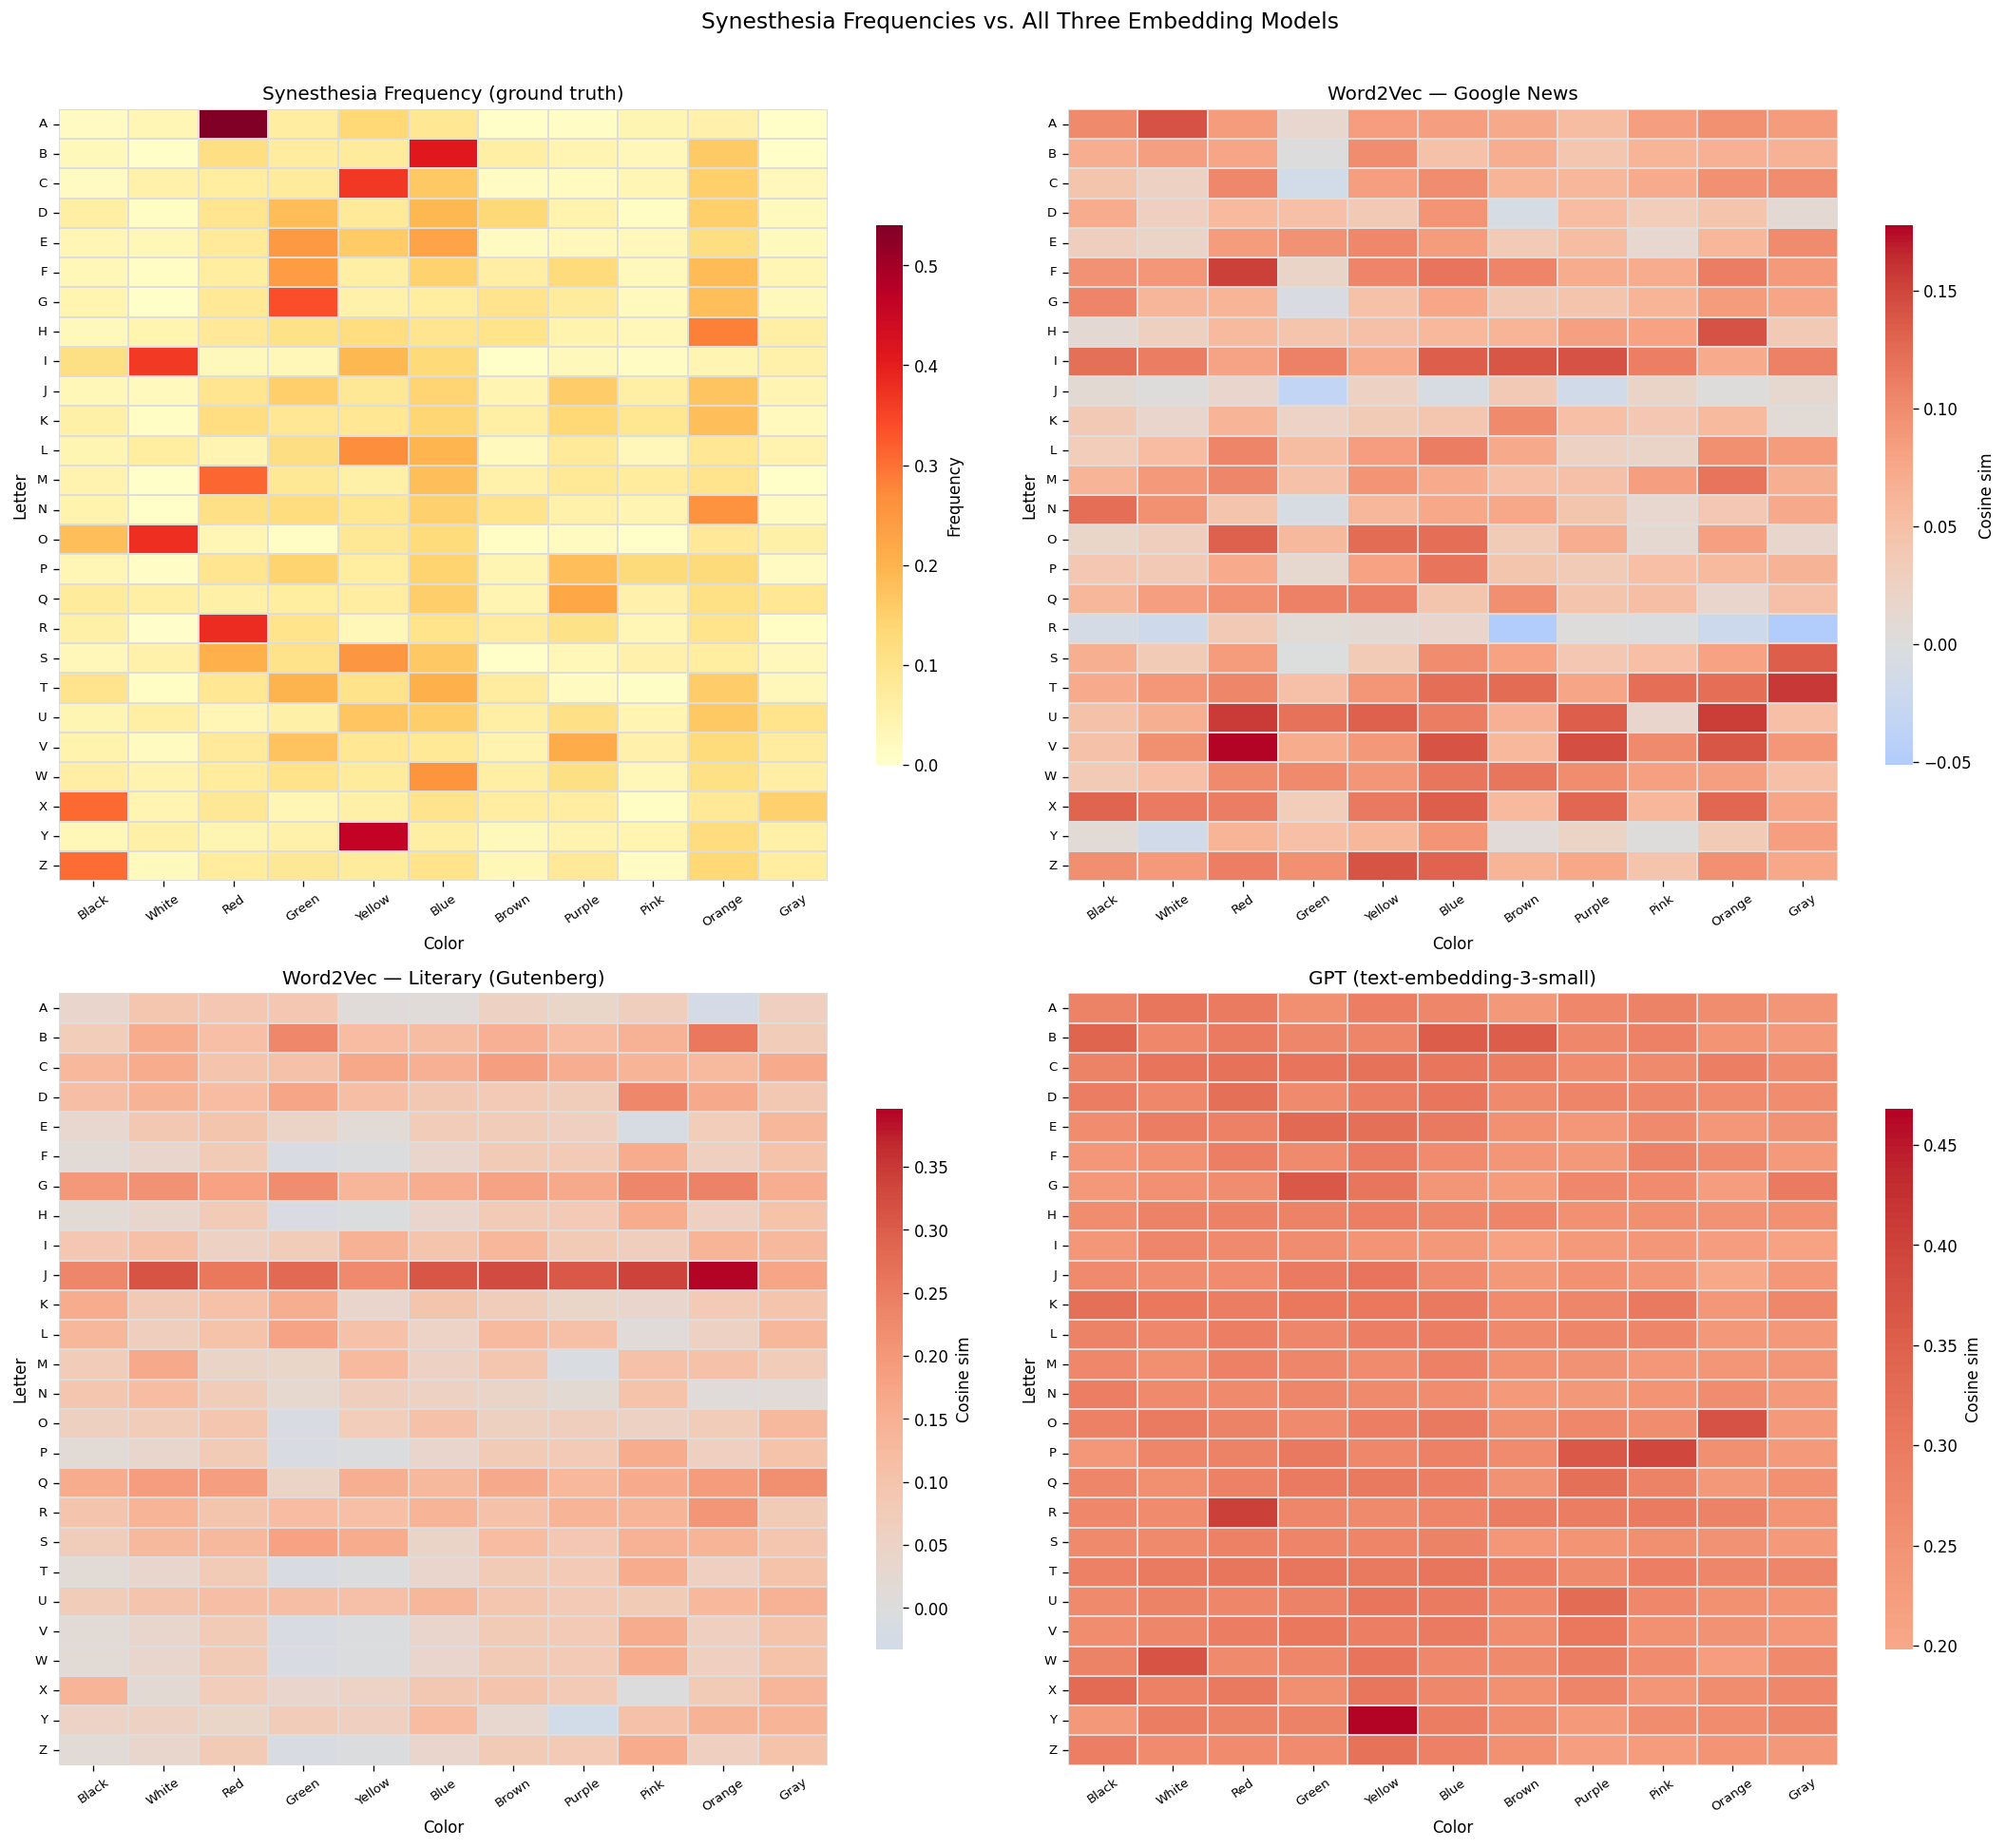

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(18, 16))
axes = axes.flatten()

_common = dict(linewidths=0.2, linecolor='#ddd', annot=False,
               yticklabels=True, xticklabels=True)

sns.heatmap(freq_df,    ax=axes[0], cmap='YlOrRd',  vmin=0,
            cbar_kws={'label': 'Frequency',  'shrink': 0.7}, **_common)
sns.heatmap(w2v_sim_df, ax=axes[1], cmap='coolwarm', center=0,
            cbar_kws={'label': 'Cosine sim', 'shrink': 0.7}, **_common)
sns.heatmap(lit_sim_df, ax=axes[2], cmap='coolwarm', center=0,
            cbar_kws={'label': 'Cosine sim', 'shrink': 0.7}, **_common)
sns.heatmap(gpt_sim_df, ax=axes[3], cmap='coolwarm', center=0,
            cbar_kws={'label': 'Cosine sim', 'shrink': 0.7}, **_common)

titles = ['Synesthesia Frequency (ground truth)',
          'Word2Vec — Google News',
          'Word2Vec — Literary (Gutenberg)',
          'GPT (text-embedding-3-small)']
for ax, title in zip(axes, titles):
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Color')
    ax.set_ylabel('Letter')
    ax.tick_params(axis='x', rotation=35, labelsize=8)
    ax.tick_params(axis='y', rotation=0,  labelsize=8)

fig.suptitle('Synesthesia Frequencies vs. All Three Embedding Models', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [26]:
freq_flat      = freq_matrix.flatten()
w2v_flat       = w2v_sim.flatten()
w2v_phrase_flat= w2v_phrase_sim.flatten()
lit_flat       = lit_sim.flatten()
phon_flat      = phon_sim.flatten()
gpt_bare_flat  = gpt_bare_sim.flatten()
gpt2_flat      = gpt2_sim.flatten()
gpt_flat       = gpt_sim.flatten()

ALL_CONDITIONS = [
    # label,                            flat array,       sim matrix
    ('W2V News — "A"',                  w2v_flat,       w2v_sim),
    ('W2V News — "letter A"',           w2v_phrase_flat,w2v_phrase_sim),
    ('W2V Literary — "A" (symbol)',     lit_flat,        lit_sim),
    ('W2V Literary — "ay" (phonetic)',  phon_flat,       phon_sim),
    ('GPT — "A" / "red"',              gpt_bare_flat,   gpt_bare_sim),
    ('GPT — "letter A" / "red"',       gpt2_flat,       gpt2_sim),
    ('GPT — "the letter A" / "the color"', gpt_flat,    gpt_sim),
]

_labels = [lbl for lbl, *_ in ALL_CONDITIONS]
CONDITION_SHORTS = dict(zip(_labels, [
    'N-A', 'N-LA', 'L-A', 'L-P', 'G-A', 'G-LA', 'G-TL'
]))

correlations = {}
print('=' * 66)
print(f'{"Model":<42}  {"Spearman ρ":>10}  {"p":>8}')
print('-' * 66)
for label, flat, _ in ALL_CONDITIONS:
    rho, p = stats.spearmanr(freq_flat, flat)
    correlations[label] = (rho, p)
    print(f'{label:<42}  {rho:>+10.4f}  {p:>8.4f}')
print('=' * 66)

Model                                       Spearman ρ         p
------------------------------------------------------------------
W2V News — "A"                                 +0.1012    0.0877
W2V News — "letter A"                          +0.1132    0.0558
W2V Literary — "A" (symbol)                    -0.0275    0.6428
W2V Literary — "ay" (phonetic)                 +0.0314    0.5973
GPT — "A" / "red"                              +0.1024    0.0838
GPT — "letter A" / "red"                       +0.4329    0.0000
GPT — "the letter A" / "the color"             +0.3381    0.0000


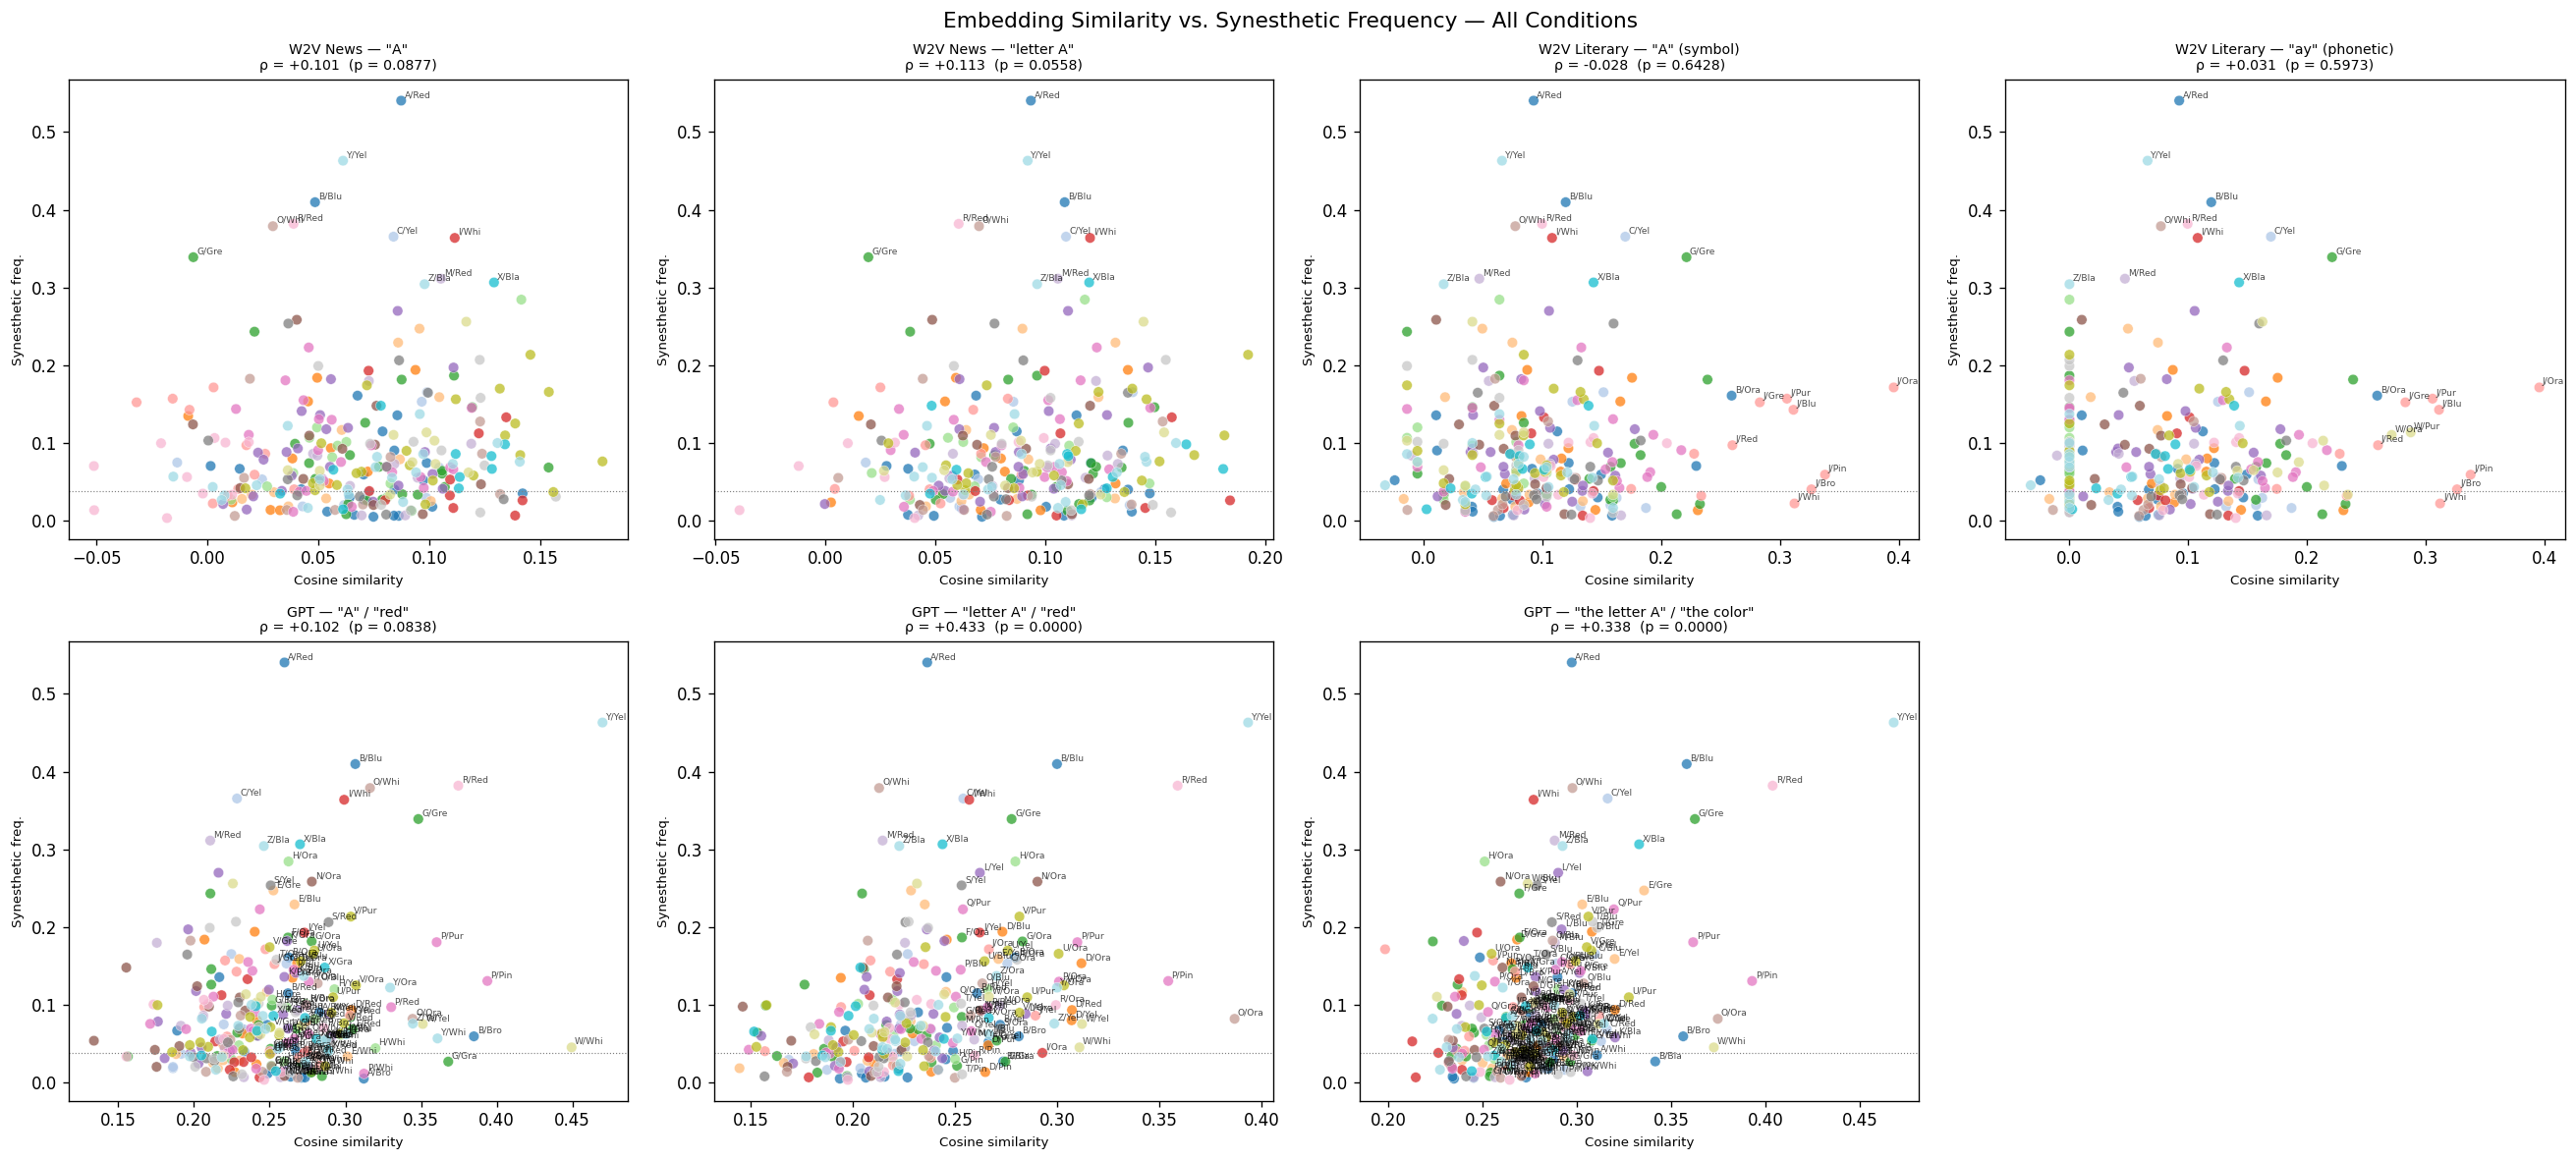

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()
letter_indices = np.repeat(np.arange(26), n_colors)

for ax, (label, flat, _) in zip(axes, ALL_CONDITIONS):
    rho, p = correlations[label]
    ax.scatter(flat, freq_flat, c=letter_indices, cmap='tab20',
               alpha=0.75, s=40, linewidths=0.3, edgecolors='white')
    ax.set_xlabel('Cosine similarity', fontsize=8)
    ax.set_ylabel('Synesthetic freq.', fontsize=8)
    ax.set_title(f'{label}\nρ = {rho:+.3f}  (p = {p:.4f})', fontsize=8.5)
    ax.axhline(1/26, color='gray', linestyle=':', linewidth=0.7)
    for i, (x, y) in enumerate(zip(flat, freq_flat)):
        if y > 0.3 or abs(x) > 0.25:
            li, ci = i // n_colors, i % n_colors
            ax.annotate(f'{LETTERS[li]}/{COLOR_NAMES[ci][:3]}', (x, y),
                        fontsize=5.5, alpha=0.7, xytext=(2,2), textcoords='offset points')

for ax in axes[len(ALL_CONDITIONS):]:
    ax.set_visible(False)

fig.suptitle('Embedding Similarity vs. Synesthetic Frequency — All Conditions', fontsize=13)
plt.tight_layout()
plt.show()

---
## 6. Per-Letter Analysis

For each letter, rank the 11 colors by (a) synesthetic frequency, (b) Word2Vec similarity, (c) GPT similarity. Check whether the top synesthetic color is predicted correctly and compute rank correlation per letter.

In [28]:
results = []
SIM_MATRICES = [(l, m) for l, _, m in ALL_CONDITIONS]

for i, letter in enumerate(LETTERS):
    freq_row = freq_matrix[i]
    modal    = COLOR_NAMES[np.argmax(freq_row)]
    row = {'Letter': letter, 'Modal': modal, 'Freq': f'{freq_row.max():.0%}'}
    for label, sim in SIM_MATRICES:
        top      = COLOR_NAMES[np.argmax(sim[i])]
        rho, _   = stats.spearmanr(freq_row, sim[i])
        short    = CONDITION_SHORTS[label]
        row[f'{short} top'] = top
        row[f'{short} ✓']   = '✓' if top == modal else '✗'
        row[f'{short} ρ']   = round(rho, 3)
    results.append(row)

results_df = pd.DataFrame(results).set_index('Letter')
# Show just the hit/rho columns for readability
hit_cols = [c for c in results_df.columns if '✓' in c]
rho_cols = [c for c in results_df.columns if ' ρ' in c]
print(results_df[['Modal','Freq'] + hit_cols + rho_cols].to_string())
print()
for label, sim in SIM_MATRICES:
    short = CONDITION_SHORTS[label]
    hits  = (results_df[f'{short} ✓'] == '✓').sum()
    print(f'  {label:<42}: {hits/26:.0%}  ({hits}/26)')

         Modal Freq N-A ✓ N-LA ✓ L-A ✓ L-P ✓ G-A ✓ G-LA ✓ G-TL ✓  N-A ρ  N-LA ρ  L-A ρ  L-P ρ  G-A ρ  G-LA ρ  G-TL ρ
Letter                                                                                                              
A          Red  54%     ✗      ✗     ✗     ✗     ✗      ✗      ✗  0.064   0.064 -0.055 -0.055 -0.373   0.700   0.536
B         Blue  41%     ✗      ✗     ✗     ✗     ✗      ✓      ✓ -0.136   0.036  0.155  0.155 -0.109   0.709   0.327
C       Yellow  37%     ✗      ✗     ✗     ✗     ✗      ✗      ✓  0.355   0.327 -0.245 -0.245  0.264   0.818   0.636
D         Blue  19%     ✓      ✓     ✗     ✗     ✗      ✗      ✗  0.436  -0.055 -0.118 -0.118  0.018   0.327   0.118
E        Green  25%     ✗      ✗     ✗     ✗     ✗      ✗      ✓  0.464   0.564 -0.273 -0.273  0.500   0.855   0.655
F        Green  24%     ✗      ✗     ✗     ✗     ✗      ✗      ✗  0.136   0.045 -0.227    NaN -0.318   0.191   0.145
G        Green  34%     ✗      ✗     ✗     ✗     ✗      ✗      ✓

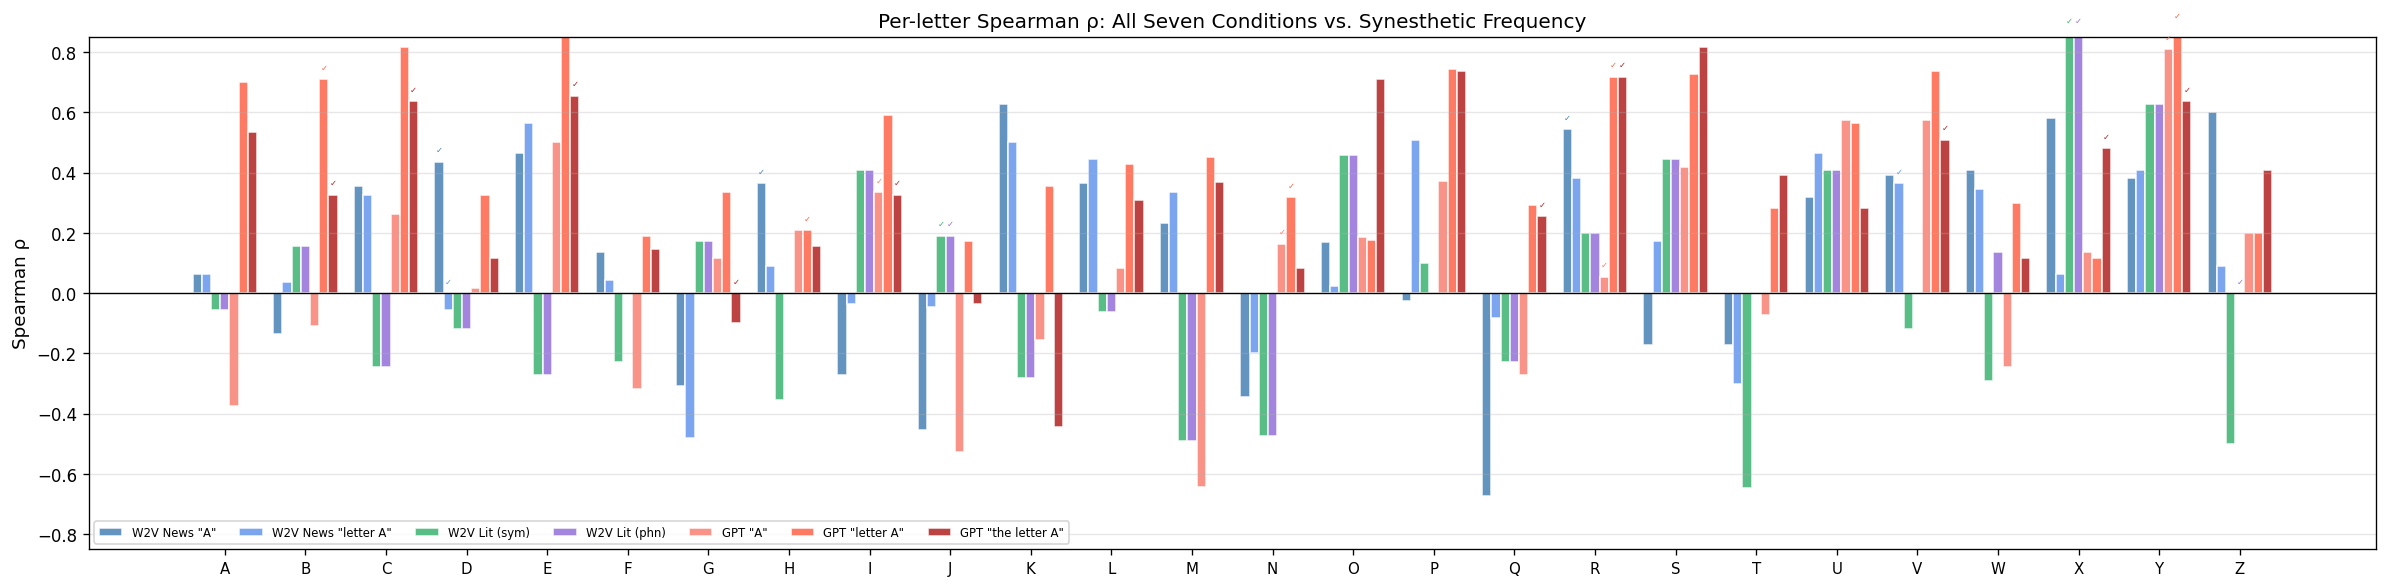

✓ = model correctly identified the modal synesthetic color for that letter


In [29]:
fig, ax = plt.subplots(figsize=(20, 5))

x       = np.arange(26)
n_c     = len(ALL_CONDITIONS)
width   = 0.8 / n_c
offsets = np.linspace(-(n_c - 1) / 2, (n_c - 1) / 2, n_c) * width

palette = ['steelblue', 'cornflowerblue', 'mediumseagreen', 'mediumpurple',
           'salmon', 'tomato', 'firebrick']
bar_labels = [
    'W2V News "A"', 'W2V News "letter A"',
    'W2V Lit (sym)', 'W2V Lit (phn)',
    'GPT "A"', 'GPT "letter A"', 'GPT "the letter A"'
]

for k, (label, _, __) in enumerate(ALL_CONDITIONS):
    short     = CONDITION_SHORTS[label]
    rho_col   = f'{short} ρ'
    match_col = f'{short} ✓'
    color     = palette[k]
    ax.bar(x + offsets[k], results_df[rho_col], width,
           label=bar_labels[k], color=color, alpha=0.85, edgecolor='white')
    for i, (_, row) in enumerate(results_df.iterrows()):
        if row[match_col] == '✓':
            rho_val = row[rho_col]
            ax.text(i + offsets[k], rho_val + 0.03 if rho_val >= 0 else 0.03,
                    '✓', ha='center', fontsize=5, color=color)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(LETTERS, fontsize=9)
ax.set_ylabel('Spearman ρ', fontsize=11)
ax.set_title('Per-letter Spearman ρ: All Seven Conditions vs. Synesthetic Frequency', fontsize=12)
ax.legend(fontsize=7, ncol=7)
ax.set_ylim(-0.85, 0.85)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
print('✓ = model correctly identified the modal synesthetic color for that letter')


---
## 7. Most Interesting Pairs

Which letter–color pairs are most strongly predicted (or mispredicted) by each model?

In [30]:
# Build a flat DataFrame of all 286 pairs
pairs = []
for i, letter in enumerate(LETTERS):
    for j, color in enumerate(COLOR_NAMES):
        pairs.append({
            'Pair': f'{letter}–{color}',
            'Letter': letter,
            'Color': color,
            'Synesthesia freq': freq_matrix[i, j],
            'W2V sim': w2v_sim[i, j],
            'GPT sim': gpt_sim[i, j],
        })
pairs_df = pd.DataFrame(pairs)

print('=== TOP 15 most common synesthetic pairs ===')
print(pairs_df.nlargest(15, 'Synesthesia freq')[['Pair','Synesthesia freq','W2V sim','GPT sim']].to_string(index=False))

print()
print('=== TOP 15 highest W2V similarity ===')
print(pairs_df.nlargest(15, 'W2V sim')[['Pair','Synesthesia freq','W2V sim','GPT sim']].to_string(index=False))

print()
print('=== TOP 15 highest GPT similarity ===')
print(pairs_df.nlargest(15, 'GPT sim')[['Pair','Synesthesia freq','W2V sim','GPT sim']].to_string(index=False))

=== TOP 15 most common synesthetic pairs ===
    Pair  Synesthesia freq   W2V sim  GPT sim
   A–Red          0.540399  0.087164 0.297213
Y–Yellow          0.463104  0.060983 0.467833
  B–Blue          0.409696  0.048381 0.358132
   R–Red          0.381866  0.038688 0.403678
 O–White          0.378844  0.029389 0.297567
C–Yellow          0.365352  0.083731 0.316215
 I–White          0.363769  0.111310 0.276977
 G–Green          0.338922 -0.006458 0.362465
   M–Red          0.311246  0.105064 0.288117
 X–Black          0.306430  0.128998 0.332910
 Z–Black          0.304207  0.097713 0.292326
H–Orange          0.284343  0.141315 0.251036
L–Yellow          0.269839  0.085600 0.290025
N–Orange          0.258393  0.040153 0.259478
  W–Blue          0.255942  0.116501 0.273849

=== TOP 15 highest W2V similarity ===
    Pair  Synesthesia freq  W2V sim  GPT sim
   V–Red          0.076120 0.177869 0.294764
  T–Gray          0.030767 0.156860 0.276631
   U–Red          0.036754 0.155733 0.277182


In [31]:
print('=' * 70)
print('SUMMARY')
print('=' * 70)
print(f'Dataset : Witthoft, Winawer & Eagleman (2015), N=6,588 synesthetes')
print(f'Letters : 26 (A–Z)   Colors : 11 basic labels   Pairs : {n_letters*n_colors}')
print()
print(f'{"Model":<42}  {"Spearman ρ":>10}  {"p":>8}  {"Hit%":>5}  Hits')
print('-' * 70)
for label, sim in SIM_MATRICES:
    short    = CONDITION_SHORTS[label]
    rho, p   = correlations[label]
    hits     = (results_df[f'{short} ✓'] == '✓').sum()
    sig      = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))
    print(f'{label:<42}  {rho:>+10.4f}  {p:>8.4f}  {hits/26:>4.0%}  {hits}/26  {sig}')
print('-' * 70)
print(f'{"Chance baseline":<42}  {"—":>10}  {"—":>8}  {1/11:>4.0%}   3/26')
print('=' * 70)
print('* p<.05  ** p<.01  *** p<.001  n.s. = not significant')

SUMMARY
Dataset : Witthoft, Winawer & Eagleman (2015), N=6,588 synesthetes
Letters : 26 (A–Z)   Colors : 11 basic labels   Pairs : 286

Model                                       Spearman ρ         p   Hit%  Hits
----------------------------------------------------------------------
W2V News — "A"                                 +0.1012    0.0877   12%  3/26  n.s.
W2V News — "letter A"                          +0.1132    0.0558    8%  2/26  n.s.
W2V Literary — "A" (symbol)                    -0.0275    0.6428    8%  2/26  n.s.
W2V Literary — "ay" (phonetic)                 +0.0314    0.5973   12%  3/26  n.s.
GPT — "A" / "red"                              +0.1024    0.0838   15%  4/26  n.s.
GPT — "letter A" / "red"                       +0.4329    0.0000   19%  5/26  ***
GPT — "the letter A" / "the color"             +0.3381    0.0000   38%  10/26  ***
----------------------------------------------------------------------
Chance baseline                                      —         —